# Projeto Final — Teste A/B

## Objetivo da análise

Avaliar se a introdução de um sistema de recomendação aprimorado aumentou a conversão dos usuários nas etapas do funil "product_page → product_cart → purchase".

<div class="alert alert-block alert-warning">
Sua declaração de objetivo enquadra corretamente o que está sendo testado (se o sistema de recomendação aprimorado aumenta a conversão ao longo do funil). Para torná-la mais completa, considere adicionar aqui os principais parâmetros técnicos (nome do teste, janela de inscrição de 7 a 21 de dezembro de 2020, data de término em 1º de janeiro de 2021, público-alvo de novos usuários da UE, 6.000 participantes esperados), para que o leitor tenha o panorama completo antes de conferir os dados em relação a esses números exatos mais adiante.
</div>

## 1. Exploração e preparação dos dados

- Carregar os quatro datasets e verificar sua estrutura.
- Conferir tipos de dados, valores ausentes e duplicados.
- Converter as colunas de data para o formato adequado.
- Verificar a consistência dos dados e dos grupos do teste.

<div class="alert alert-block alert-success">
Seu plano seção por seção (cobrindo preparação de dados, análise exploratória, avaliação do teste A/B e conclusões finais) está bem organizado e corresponde ao que você realmente entrega posteriormente no notebook — um roteiro claro para o leitor.
</div>

## 2. Análise exploratória dos dados

- Analisar a conversão nas etapas do funil product_page → product_cart → purchase".
- Comparar o número de eventos por usuário entre os grupos A e B.
- Verificar a distribuição dos participantes entre os grupos.
- Analisar a distribuição dos eventos ao longo dos dias.
- Identificar possíveis particularidades que possam afetar a avaliação do teste.

## 3. Avaliação do teste A/B

- Comparar as taxas de conversão dos grupos A e B em cada etapa do funil.
- Verificar se o grupo B apresentou aumento de pelo menos 10% nas conversões.
- Aplicar o teste estatístico z para proporções.
- Avaliar se as diferenças observadas são estatisticamente significativas.

## 4. Conclusões e recomendações

- Resumir os principais resultados da análise exploratória.
- Apresentar a conclusão sobre a eficácia do teste A/B.
- Indicar se o novo sistema de recomendação apresentou evidências de melhoria na conversão.

## 5. Carregamento dos dados

Nesta etapa, serão carregados os quatro conjuntos de dados fornecidos para o projeto:
- eventos de marketing;
- novos usuários;
- eventos dos usuários;
- participantes do teste A/B.

<div class="alert alert-block alert-warning">
O notebook mistura dois esquemas de numeração: o plano de alto nível ('1.–4.' acima) e a implementação real, que reinicia a numeração em '5. Carregamento dos dados' e mais tarde reutiliza 'Análise exploratória dos dados' como '6.' Isso dificulta um pouco a navegação entre o plano e o trabalho efetivamente realizado. Considere alinhar os cabeçalhos do plano diretamente com os cabeçalhos da implementação, em vez de duplicá-los com uma sequência de numeração separada.
</div>

In [1]:
import pandas as pd

marketing_events = pd.read_csv('/datasets/ab_project_marketing_events_us.csv')
new_users = pd.read_csv('/datasets/final_ab_new_users_upd_us.csv')
events = pd.read_csv('/datasets/final_ab_events_upd_us.csv')
participants = pd.read_csv('/datasets/final_ab_participants_upd_us.csv')

print('Marketing events:')
display(marketing_events.head())

print('New users:')
display(new_users.head())

print('Events:')
display(events.head())

print('Participants:')
display(participants.head())

Marketing events:


,name,regions,start_dt,finish_dt
0,Christmas&New Year Promo,"EU, N.America",2020-12-25,2021-01-03
1,St. Valentine's Day Giveaway,"EU, CIS, APAC, N.America",2020-02-14,2020-02-16
2,St. Patric's Day Promo,"EU, N.America",2020-03-17,2020-03-19
3,Easter Promo,"EU, CIS, APAC, N.America",2020-04-12,2020-04-19
4,4th of July Promo,N.America,2020-07-04,2020-07-11


New users:


,user_id,first_date,region,device
0,D72A72121175D8BE,2020-12-07,EU,PC
1,F1C668619DFE6E65,2020-12-07,N.America,Android
2,2E1BF1D4C37EA01F,2020-12-07,EU,PC
3,50734A22C0C63768,2020-12-07,EU,iPhone
4,E1BDDCE0DAFA2679,2020-12-07,N.America,iPhone


Events:


,user_id,event_dt,event_name,details
0,E1BDDCE0DAFA2679,2020-12-07 20:22:03,purchase,99.99
1,7B6452F081F49504,2020-12-07 09:22:53,purchase,9.99
2,9CD9F34546DF254C,2020-12-07 12:59:29,purchase,4.99
3,96F27A054B191457,2020-12-07 04:02:40,purchase,4.99
4,1FD7660FDF94CA1F,2020-12-07 10:15:09,purchase,4.99


Participants:


,user_id,group,ab_test
0,D1ABA3E2887B6A73,A,recommender_system_test
1,A7A3664BD6242119,A,recommender_system_test
2,DABC14FDDFADD29E,A,recommender_system_test
3,04988C5DF189632E,A,recommender_system_test
4,4FF2998A348C484F,A,recommender_system_test


<div class="alert alert-block alert-success">
Todos os quatro conjuntos de dados obrigatórios são carregados a partir dos caminhos de arquivo corretos, e cada um deles é pré-visualizado com um rótulo de impressão (print label) claro antes da chamada de display(). Isso satisfaz plenamente a etapa de 'carregar os conjuntos de dados e verificar sua estrutura'.
</div>

In [2]:
datasets = {
    'Marketing events': marketing_events,
    'New users': new_users,
    'Events': events,
    'Participants': participants
}

for name, df in datasets.items():
    print(f'\n{name}')
    print('Formato:', df.shape)
    print('Valores ausentes:')
    print(df.isna().sum())
    print('Duplicados:', df.duplicated().sum())
    print('Tipos:')
    print(df.dtypes)


Marketing events
Formato: (14, 4)
Valores ausentes:
name         0
regions      0
start_dt     0
finish_dt    0
dtype: int64
Duplicados: 0
Tipos:
name         object
regions      object
start_dt     object
finish_dt    object
dtype: object

New users
Formato: (58703, 4)
Valores ausentes:
user_id       0
first_date    0
region        0
device        0
dtype: int64
Duplicados: 0
Tipos:
user_id       object
first_date    object
region        object
device        object
dtype: object

Events
Formato: (423761, 4)
Valores ausentes:
user_id            0
event_dt           0
event_name         0
details       363447
dtype: int64
Duplicados: 0
Tipos:
user_id        object
event_dt       object
event_name     object
details       float64
dtype: object

Participants
Formato: (14525, 3)
Valores ausentes:
user_id    0
group      0
ab_test    0
dtype: int64
Duplicados: 0
Tipos:
user_id    object
group      object
ab_test    object
dtype: object


<div class="alert alert-block alert-warning">
Percorrer os quatro datasets em um único passo para verificar shape, valores ausentes, duplicatas e dtypes está bem organizado, e sua leitura dos resultados (nenhuma duplicata de linha completa, valores ausentes restritos a 'details') está correta. Tenha em mente que verificar duplicatas em linhas completas não vai capturar um user_id que aparece duas vezes com um valor diferente de group/ab_test — verificar duplicatas no nível de user_id para new_users e participants aqui teria revelado o problema de 'usuários com dois valores de group' bem mais cedo.
</div>

In [3]:
marketing_events['start_dt'] = pd.to_datetime(marketing_events['start_dt'])
marketing_events['finish_dt'] = pd.to_datetime(marketing_events['finish_dt'])
new_users['first_date'] = pd.to_datetime(new_users['first_date'])
events['event_dt'] = pd.to_datetime(events['event_dt'])

print(marketing_events.dtypes)
print(new_users.dtypes)
print(events.dtypes)

name                 object
regions              object
start_dt     datetime64[ns]
finish_dt    datetime64[ns]
dtype: object
user_id               object
first_date    datetime64[ns]
region                object
device                object
dtype: object
user_id               object
event_dt      datetime64[ns]
event_name            object
details              float64
dtype: object


<div class="alert alert-block alert-success">
Todas as colunas de data relevantes (start_dt, finish_dt, first_date, event_dt) são corretamente convertidas para datetime — exatamente o que é necessário para a filtragem baseada em tempo que você faz mais adiante, como a janela de conversão de 14 dias.
</div>

### Conclusão da preparação

Os dados não apresentam duplicados ou valores ausentes nas informações principais. Os valores ausentes em "details" são esperados, pois representam informações adicionais disponíveis apenas para determinados eventos. As colunas de data foram convertidas para o formato "datetime".

<div class="alert alert-block alert-success">
Seu resumo escrito reflete com precisão os resultados da preparação — sem duplicatas, valores ausentes limitados a (e esperados em) details, e datas convertidas para datetime. Um fechamento claro antes de avançar para a análise exploratória.
</div>

In [4]:
## 6. Análise exploratória dos dados

test_users = participants[
    participants['ab_test'] == 'recommender_system_test'
].copy()

test_users['group'].value_counts()

A    2747
B     928
Name: group, dtype: int64

<div class="alert alert-block alert-success">
Filtrar os participantes para recommender_system_test antes de contar os grupos está exatamente correto — isso fornece a divisão real de grupos para o teste que você está avaliando (2.747 vs. 928), em vez de misturá-la com o interface_eu_test, que não tem relação. Isso evidencia corretamente o desequilíbrio de grupos que você revisita mais adiante.
</div>

In [5]:
events['user_id'].value_counts().describe()

count    58703.000000
mean         7.218728
std          4.122609
min          1.000000
25%          4.000000
50%          6.000000
75%          9.000000
max         36.000000
Name: user_id, dtype: float64

<div class="alert alert-block alert-warning">
Isso fornece uma visão geral útil de eventos por usuário, mas é calculado sobre toda a tabela de eventos, sem se restringir aos participantes do recommender_system_test. Como o objetivo é verificar se os eventos por usuário estão distribuídos de forma equilibrada entre os grupos A e B, esta célula funciona principalmente como uma linha de base geral — a resposta real só aparece quando você separa por grupo na célula seguinte. Uma breve nota esclarecendo isso deixaria sua intenção mais clara.
</div>

In [6]:
rec_events = events.merge(
    test_users[['user_id', 'group']],
    on='user_id'
)

rec_events.groupby('group')['user_id'].value_counts().groupby(level=0).describe()

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
A,2747.0,6.780852,3.729768,1.0,4.0,6.0,9.0,24.0
B,928.0,5.691810,3.450350,1.0,3.0,5.0,8.0,28.0


<div class="alert alert-block alert-success">
Este merge usa corretamente a tabela test_users já filtrada em vez da tabela completa participants, portanto as contagens de eventos por grupo (média ≈ 6,78 para A vs. ≈ 5,69 para B) são calculadas na população correta, específica do teste.
</div>

In [7]:
participants.groupby('user_id')['group'].nunique().value_counts()

1    13197
2      441
Name: group, dtype: int64

<div class="alert alert-block alert-success">
Ótima observação — descobrir que 441 usuários têm mais de um valor distinto de grupo é exatamente o tipo de particularidade dos dados que vale a pena sinalizar antes de confiar na configuração do teste, e isso prepara bem o terreno para sua investigação de sobreposição mais adiante.
</div>

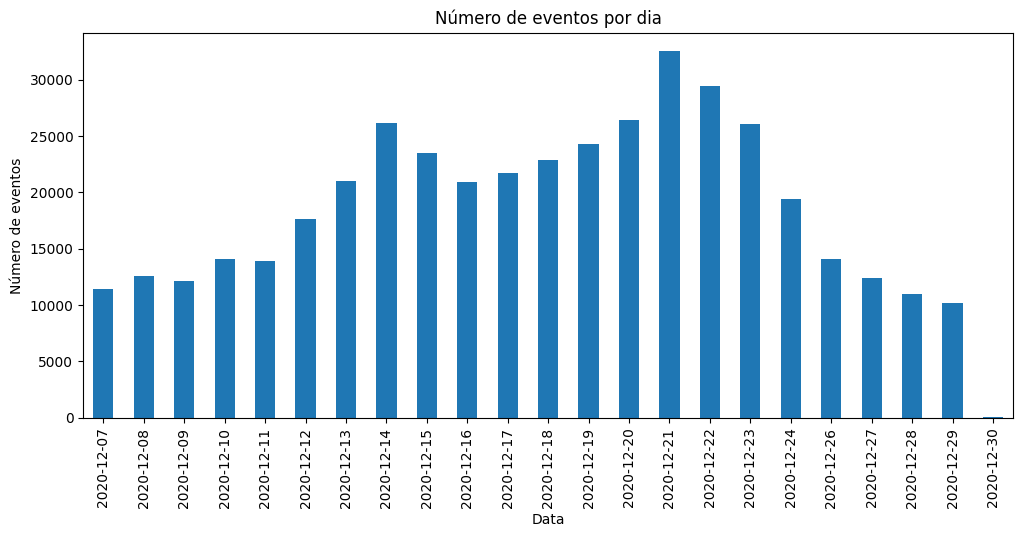

In [8]:
events['event_dt'].dt.date.value_counts().sort_index().plot(
    kind='bar',
    figsize=(12, 5),
    title='Número de eventos por dia'
)

import matplotlib.pyplot as plt

plt.xlabel('Data')
plt.ylabel('Número de eventos')
plt.show()

<div class="alert alert-block alert-success">
Este é um gráfico bem construído: os rótulos dos eixos e o título o tornam autoexplicativo, e ele mostra claramente os eventos diários subindo até um pico por volta de 21 de dezembro, depois declinando, com uma lacuna visível em 25 de dezembro e uma barra quase invisível em 30 de dezembro.
</div>

In [9]:
events['event_date'] = events['event_dt'].dt.date
events.groupby('event_date')['event_name'].count()

event_date
2020-12-07    11385
2020-12-08    12547
2020-12-09    12122
2020-12-10    14077
2020-12-11    13864
2020-12-12    17634
2020-12-13    20985
2020-12-14    26184
2020-12-15    23469
2020-12-16    20909
2020-12-17    21751
2020-12-18    22871
2020-12-19    24273
2020-12-20    26425
2020-12-21    32559
2020-12-22    29472
2020-12-23    26108
2020-12-24    19399
2020-12-26    14058
2020-12-27    12420
2020-12-28    11014
2020-12-29    10146
2020-12-30       89
Name: event_name, dtype: int64

<div class="alert alert-block alert-success">
A derivação de event_date e a agregação com groupby fornece os números diários exatos que sustentam o gráfico, confirmando corretamente a ausência do registro de 25 de dezembro e a queda acentuada de 10.146 para 89 eventos. Dica idiomática menor para o futuro: events['event_date'].value_counts().sort_index() daria o mesmo resultado com menos código — apenas uma preferência de estilo, não um problema.
</div>

### Observação sobre a distribuição temporal dos eventos

A distribuição diária dos eventos apresenta uma possível inconsistência na parte final do período de observação. Não há registros em 25/12/2020, embora existam eventos nos dias imediatamente anterior e posterior. Além disso, o número de eventos cai de 10.146 em 29/12 para apenas 89 em 30/12, sem registros posteriores.

Esse comportamento sugere que os dados podem estar incompletos ou truncados no final do período de observação. Essa limitação é importante para a análise do teste A/B, pois usuários registrados próximos ao final da janela podem não ter todos os seus eventos, especialmente compras, registrados dentro da janela de conversão de 14 dias.

<div class="alert alert-block alert-success">
Sua observação escrita é precisa e bem fundamentada: você identifica corretamente as entradas ausentes por volta do dia 25 de dezembro e a queda acentuada nos eventos no final do período, e relaciona isso à consequência prática de que usuários registrados perto do final da janela podem não ter sua janela completa de conversão de 14 dias capturada.
</div>

In [10]:
participants.groupby(['ab_test', 'group'])['user_id'].count()

ab_test                  group
interface_eu_test        A        5467
                         B        5383
recommender_system_test  A        2747
                         B         928
Name: user_id, dtype: int64

<div class="alert alert-block alert-success">
Agrupar por ab_test e group é um ótimo passo de diagnóstico — isso revela que participants mistura dois experimentos (interface_eu_test e recommender_system_test) e que os grupos do recommender_system_test estão fortemente desbalanceados (2.747 vs. 928).
</div>

In [11]:
test_users = participants[participants['ab_test'] == 'recommender_system_test']

test_users = test_users.merge(new_users[['user_id', 'region']], on='user_id')

test_users['region'].value_counts()

EU           3481
N.America     119
APAC           45
CIS            30
Name: region, dtype: int64

<div class="alert alert-block alert-warning">
O merge e a divisão regional estão corretos, e o resultado (EU 3.481, N.America 119, APAC 45, CIS 30) mostra claramente que a população de teste não foi restrita à EU como pretendido. Isso é identificado corretamente, mas só é interpretado bem mais adiante, na sua conclusão final — uma breve observação aqui facilitaria o acompanhamento do notebook, sem exigir que o leitor carregue essa informação ao longo de muitas células.
</div>

In [12]:
rec_users = set(participants.loc[participants['ab_test'] == 'recommender_system_test', 'user_id'])
interface_users = set(participants.loc[participants['ab_test'] == 'interface_eu_test', 'user_id'])

len(rec_users & interface_users)

887

In [13]:
rec_users = set(
    participants.loc[
        participants['ab_test'] == 'recommender_system_test',
        'user_id'
    ]
)

interface_users = set(
    participants.loc[
        participants['ab_test'] == 'interface_eu_test',
        'user_id'
    ]
)

overlap_users = rec_users & interface_users

print('Usuários presentes nos dois testes:', len(overlap_users))

Usuários presentes nos dois testes: 887


<div class="alert alert-block alert-warning">
Quantificar a sobreposição de 887 usuários entre recommender_system_test e interface_eu_test e armazená-la em overlap_users para reutilização futura é uma boa prática. No entanto, esse cálculo é idêntico ao realizado na célula imediatamente anterior — os mesmos dois conjuntos, a mesma interseção, apenas com nomes de variáveis diferentes e uma instrução print — e o resultado da versão anterior não é reutilizado em nenhum lugar. Considere manter apenas uma versão desse cálculo para evitar trabalho duplicado.
</div>

In [17]:
rec_participants = participants[
    (participants['ab_test'] == 'recommender_system_test') &
    (~participants['user_id'].isin(overlap_users))
][['user_id', 'group']]

rec_events = events.merge(
    rec_participants,
    on='user_id',
    how='inner'
)

print('Participantes após exclusão da sobreposição:')
print(rec_participants.groupby('group')['user_id'].nunique())

print('\nEventos por grupo:')
display(
    rec_events.groupby(['group', 'event_name'])['user_id']
    .nunique()
    .unstack()
)

Participantes após exclusão da sobreposição:
group
A    2082
B     706
Name: user_id, dtype: int64

Eventos por grupo:


event_name,login,product_cart,product_page,purchase
group,,,,
A,2082,631,1360,652
B,705,195,397,198


<div class="alert alert-block alert-warning">
A lógica de exclusão aqui está correta: rec_participants filtra para recommender_system_test e remove os 887 overlap_users, depois faz um novo merge com events, resultando em contagens (2.082 para A, 706 para B) consistentes com suas descobertas sobre a sobreposição. Uma pequena observação que vale a pena mencionar: rec_participants reporta 706 usuários únicos no grupo B, mas a contagem de logins na tabela 'Eventos por grupo' abaixo é 705 — o que significa que um participante do grupo B não tem nenhum evento de login. Isso não muda suas conclusões gerais, mas uma breve menção ajudaria o leitor a não ficar confuso com essa discrepância.
</div>

In [18]:
rec_events = rec_events.merge(
    new_users[['user_id', 'first_date']],
    on='user_id',
    how='left'
)

rec_events = rec_events[
    (rec_events['event_dt'].dt.date >= rec_events['first_date'].dt.date) &
    (rec_events['event_dt'].dt.date <= (rec_events['first_date'] + pd.Timedelta(days=14)).dt.date)
]

<div class="alert alert-block alert-success">
A janela de conversão de 14 dias é aplicada corretamente e na ordem certa: você faz o merge de first_date e, em seguida, mantém apenas os eventos entre first_date e first_date + 14 dias, aplicado após a exclusão de sobreposição — exatamente a sequência correta.
</div>

In [19]:
funnel = rec_events.groupby(
    ['group', 'event_name']
)['user_id'].nunique().unstack()

# Conversão de cada etapa em relação ao total de usuários que fizeram login
for event in ['product_page', 'product_cart', 'purchase']:
    funnel[f'{event}_conversion'] = funnel[event] / funnel['login']

funnel[
    ['login', 'product_page', 'product_cart', 'purchase',
     'product_page_conversion', 'product_cart_conversion', 'purchase_conversion']
]

event_name,login,product_page,product_cart,purchase,product_page_conversion,product_cart_conversion,purchase_conversion
group,,,,,,,
A,2082,1360,631,652,0.653218,0.303074,0.313160
B,705,397,195,198,0.563121,0.276596,0.280851


<div class="alert alert-block alert-success">
Esta tabela de funil é construída inteiramente a partir de rec_events devidamente filtrados (sobreposição removida, janela de 14 dias aplicada), com todas as três taxas de conversão utilizando consistentemente login como denominador. Esta é a única versão confiável do funil que alimenta corretamente seu teste-z e as conclusões finais.
</div>

## Teste de significância estatística

Para verificar se as diferenças observadas entre os grupos A e B são estatisticamente significativas, será aplicado o teste z para comparação de proporções em cada etapa do funil.

<div class="alert alert-block alert-success">
Esta introdução está clara e leva diretamente ao teste-z corrigido. O bloco preliminar duplicado do teste-z e sua conclusão contraditória foram removidos, de modo que esta seção agora flui para uma análise estatística única e consistente.
</div>

In [20]:
from statsmodels.stats.proportion import proportions_ztest

events_to_test = ['product_page', 'product_cart', 'purchase']

for event in events_to_test:
    successes = [
        funnel.loc['A', event],
        funnel.loc['B', event]
    ]
    
    totals = [
        funnel.loc['A', 'login'],
        funnel.loc['B', 'login']
    ]
    
    stat, p_value = proportions_ztest(successes, totals)
    
    print(event)
    print('Estatística z:', stat)
    print('p-value:', p_value)
    print()

product_page
Estatística z: 4.283626682686839
p-value: 1.8387132766752543e-05

product_cart
Estatística z: 1.3306487024844451
p-value: 0.18330462936588865

purchase
Estatística z: 1.610487921566414
p-value: 0.10729138019857214



<div class="alert alert-block alert-warning">
A implementação do teste-z está correta — [count_A, count_B] como sucessos e [login_A, login_B] como totais, aplicados ao funil corrigido — e os p-values resultantes (product_page ≈ 1.8e-5, product_cart ≈ 0.183, purchase ≈ 0.107) correspondem ao que é reportado na sua conclusão final. Como uma melhoria opcional: já que você está executando três testes-z separados no mesmo par de grupos, considere aplicar uma correção para comparações múltiplas (e.g., Bonferroni) antes de decidir em quais diferenças confiar — não é obrigatório, mas é uma boa prática para testes de hipóteses futuros.
</div>

### Conclusão do teste A/B

Após excluir os usuários que participaram simultaneamente dos dois testes, o grupo B apresentou conversões inferiores ao grupo A em todas as etapas do funil.

O grupo B não atingiu o aumento esperado de pelo menos 10% em nenhuma etapa:
- product_page: 13,79% abaixo do grupo A;
- product_cart: 8,74% abaixo do grupo A;
- purchase: 10,32% abaixo do grupo A.

O teste z mostrou diferença estatisticamente significativa apenas para product_page (p < 0,001). Para product_cart (p = 0,183) e purchase (p = 0,107), as diferenças não foram estatisticamente significativas.

Portanto, não há evidências de que o novo sistema de recomendação tenha melhorado a conversão.

<div class="alert alert-block alert-success">
Esta conclusão é precisa e está totalmente consistente com o resultado do teste-z acima dela: os percentuais (13,79%, 8,74%, 10,32% abaixo do grupo A) e os valores-p (p<0,001, p=0,183, p=0,107) estão corretamente reportados, oferecendo ao notebook uma conclusão estatística clara e inequívoca.
</div>

## Conclusão final

A análise identificou problemas importantes na configuração e na qualidade dos dados do teste. O experimento teve 2.788 participantes válidos após a exclusão dos 887 usuários que participaram simultaneamente de dois testes, abaixo dos 6.000 participantes esperados. Além disso, os grupos ficaram desbalanceados (2.082 usuários no grupo A e 706 no grupo B).

Também foram identificados participantes de regiões fora da UE, embora o público-alvo do teste fosse formado por novos usuários da UE.

A distribuição diária dos eventos apresenta uma queda incomum no final do período: não há eventos em 25 de dezembro, apenas 89 eventos em 30 de dezembro e nenhum evento em 31 de dezembro ou 1º de janeiro. Isso indica possível truncamento ou coleta incompleta dos dados, o que pode afetar principalmente as conversões de usuários cadastrados próximos ao final do período.

O calendário de marketing também mostra uma sobreposição com a promoção de Natal e Ano Novo, realizada de 25 de dezembro de 2020 a 3 de janeiro de 2021. Essa campanha coincide com o final do período do teste e pode ter influenciado o comportamento dos usuários e as conversões.

Após as correções, o grupo B apresentou conversões inferiores ao grupo A em todas as etapas e não atingiu o aumento esperado de 10%. O teste z indicou diferença estatisticamente significativa apenas em product_page, enquanto product_cart e purchase não apresentaram diferenças estatisticamente significativas.

Portanto, não há evidências de que o novo sistema de recomendação tenha melhorado a conversão. Além disso, devido ao desbalanceamento dos grupos, à participação de usuários fora da UE, à sobreposição entre testes, à campanha de marketing e à possível truncagem dos dados no final do período, os resultados devem ser interpretados com cautela. Recomenda-se revisar a configuração e a coleta de dados antes de realizar um novo teste.

<div class="alert alert-block alert-success">
Ótima correção aqui — a contagem de participantes agora indica corretamente 2.788 participantes válidos (2.747 + 928 − 887), coincidindo com as contagens em nível de grupo que você cita logo em seguida (2.082 + 706 = 2.788), e é comparada de forma consistente com o esperado de 6.000. O restante da sua conclusão final une o desequilíbrio entre grupos, os participantes fora da UE, o truncamento de dados, a sobreposição com a campanha de marketing e os resultados estatísticos em uma recomendação completa e bem fundamentada para revisar a configuração do teste antes de executá-lo novamente.
</div>